# III. Analyse spatiale et temporelle des performances environnementales

Pour étudier l'évolution des performances environnementales entre 1995 et 2022, nous allons reconstituer une base de données historique. La reconstruction présente trois limites principales :

- **Les valeurs manquantes :** certains indicateurs n'ont pas été mesurés pour certains pays ou certaines années. 

- **Les indicateurs non applicables :** certaines valeurs sont absentes car l'indicateur ne s'applique pas au pays concerné, comme les indicateurs liés à la pêche pour les pays sans accès à la mer.

- **L'hétérogénéité temporelle :** les méthodes de mesure des indicateurs ont pu évoluer au cours des dernières décennies, limitant  la comparabilité des valeurs entre les années.

Malgré ces limites, nous adoptons une méthodologie cohérente sur l'ensemble de la période étudiée afin de comparer:

- **L'EPI historique**, calculé à partir des pondérations officielles de l'EPI 2022.

- **Le nouvel EPI historique**, calculé à partir des indicateurs et pondérations retenus dans la partie précédente.

L'EPI global constituant le principal outil de synthèse susceptible d'orienter les décisions des pouvoirs publics, nous choisissons de ne pas approfondir l'évolution des sous-indices intermédiaires.

## A. Construction et nettoyage des bases historiques (1995-2022)

### Construction de la base historique

Nous fusionnons les 40 fichiers CSV contenant les données historiques des indicateurs (disponibles dans `raw_data/2022-epi-indicators-time-series-na`) à l'aide de la fonction `construire_base_historique` (implémentée dans `niels/dynamique.py`) qui effectue des jointures successives.

In [1]:
import pandas as pd

# Importation des fonctions implémentées dans le fichier niels/dynamique.py
from niels.dynamique import (
    construire_base_historique,
    ajouter_regions,
    imputer_valeurs_manquantes,
    charger_ponderations_nouvelles,
    charger_ponderations_officielles,
    calculer_epi
)

dossier = "raw_data/2022-epi-indicators-time-series-na"
chemin_excel = "raw_data/2022-epi.xlsx"
chemin_poids = "niels/clear_indices.xlsx"

df_global = construire_base_historique(dossier)
df_global.head()

,code,iso,country,year,BCA,BHV,CDA,CHA,COE,FGA,...,SPI,SPU,TBG,TBN,TCL,USD,UWD,VOE,WTL,WWT
0,4,AFG,Afghanistan,1995,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,0.4,37.333333,0.0,0.0,33.446525,13.874244,14.164265,39.298331,100.0,0.0
1,4,AFG,Afghanistan,1996,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,0.4,37.333333,0.0,0.0,33.446525,14.156227,14.444992,39.298331,100.0,0.0
2,4,AFG,Afghanistan,1997,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,0.4,37.333333,0.0,0.0,33.446525,13.232921,13.503853,39.298331,100.0,0.0
3,4,AFG,Afghanistan,1998,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,0.4,37.333333,0.0,0.0,33.446525,12.554152,12.809990,39.298331,100.0,0.0
4,4,AFG,Afghanistan,1999,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,0.4,37.333333,0.0,0.0,33.446525,12.083639,12.322927,39.298331,100.0,0.0


Nous conservons les 180 pays présents dans l'EPI 2022 et associons à chacun sa région géographique à l'aide de la fonction `ajouter_regions`. 

In [2]:
df_etude_na = ajouter_regions(df_global, chemin_excel)
print("Nombre de pays :", df_etude_na["iso"].nunique())
print("Nombre de lignes :", len(df_etude_na))
df_etude_na.head()

Nombre de pays : 180
Nombre de lignes : 5040


,code,iso,country,year,BCA,BHV,CDA,CHA,COE,FGA,...,SPU,TBG,TBN,TCL,USD,UWD,VOE,WTL,WWT,region
0,4,AFG,Afghanistan,1995,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,37.333333,0.0,0.0,33.446525,13.874244,14.164265,39.298331,100.0,0.0,Southern Asia
1,4,AFG,Afghanistan,1996,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,37.333333,0.0,0.0,33.446525,14.156227,14.444992,39.298331,100.0,0.0,Southern Asia
2,4,AFG,Afghanistan,1997,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,37.333333,0.0,0.0,33.446525,13.232921,13.503853,39.298331,100.0,0.0,Southern Asia
3,4,AFG,Afghanistan,1998,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,37.333333,0.0,0.0,33.446525,12.554152,12.809990,39.298331,100.0,0.0,Southern Asia
4,4,AFG,Afghanistan,1999,15.772571,41.8988,0.0,7.151127,46.499051,NaN,...,37.333333,0.0,0.0,33.446525,12.083639,12.322927,39.298331,100.0,0.0,Southern Asia


### Traitement des valeurs manquantes

Les auteurs du rapport ont déjà traité une partie des données manquantes par interpolation linéaire et prolongement constant aux extrémités des séries. Pour les indicateurs non applicables, ils redistribuent leurs poids entre les autres indicateurs.
Par souci de simplicité, nous choisissons de remplacer les valeurs manquantes restantes par la moyenne régionale de l'indicateur pour l'année considérée (`imputer_valeurs_manquantes`). Les pondérations restent ainsi constantes, mais le classement de 2022 pourra différer du classement officiel.

In [3]:
df_etude = imputer_valeurs_manquantes(df_etude_na)
indicateurs = df_etude.columns.drop(["code", "iso", "country", "year", "region"])
print("Valeurs manquantes avant imputation :", df_etude_na[indicateurs].isna().sum().sum())
print("Valeurs manquantes après imputation :", df_etude[indicateurs].isna().sum().sum())

Valeurs manquantes avant imputation : 12964
Valeurs manquantes après imputation : 0


### Calcul des indices historiques

Notre base historique est désormais prête. Nous récupérons les pondérations officielles et les nouvelles pondérations, puis calculons les deux indices pour chaque pays et chaque année à l'aide de la fonction `calculer_epi`.

In [4]:
poids_officiels = charger_ponderations_officielles(chemin_excel)
poids_nouveaux = charger_ponderations_nouvelles(chemin_poids, chemin_excel)

print("Nombre d'indicateurs officiels :", len(poids_officiels))
print("Nombre d'indicateurs retenus :", len(poids_nouveaux))

df_final = calculer_epi(df_etude, poids_officiels, "EPI_officiel")
df_final = calculer_epi(df_final, poids_nouveaux, "EPI_new")

df_final[["country", "region", "year", "EPI_officiel", "EPI_new"]].head()


Nombre d'indicateurs officiels : 40
Nombre d'indicateurs retenus : 26


,country,region,year,EPI_officiel,EPI_new
0,Afghanistan,Southern Asia,1995,20.366574,22.924066
1,Afghanistan,Southern Asia,1996,20.381763,22.998202
2,Afghanistan,Southern Asia,1997,20.313650,22.975578
3,Afghanistan,Southern Asia,1998,20.212564,22.883018
4,Afghanistan,Southern Asia,1999,20.146792,22.676660


## B. Analyse et comparaison des trajectoires environnementales selon les deux indices

À partir de la base historique précédemment construite, nous étudions l’évolution des performances environnementales entre 1995 et 2022. Les fonctions de visualisation sont implémentées dans le fichier `niels/dynamique_graphique.py`.

In [5]:
from niels.dynamique_graphique import (
    graphique_evolution_epi_moyen_median_mondial,
    graphique_evolution_epi_moyen_par_region,
    graphique_classement_variation_epi_par_pays,
    graphique_evolution_classement_par_region,
    tableau_synthese_evolution_par_region
)

Avant de comparer les deux indices, nous vérifions la disponibilité des scores pour chaque année.

In [6]:
df_final.groupby("year")[["EPI_officiel", "EPI_new"]].count()

,EPI_officiel,EPI_new
year,,
1995,180,180
1996,180,180
1997,180,180
1998,180,180
1999,180,180
2000,180,180
2001,180,180
2002,180,180
2003,180,180


### Évolution des performances mondiales

Nous observons tout d’abord l’évolution des scores moyens et médians à l’échelle mondiale.

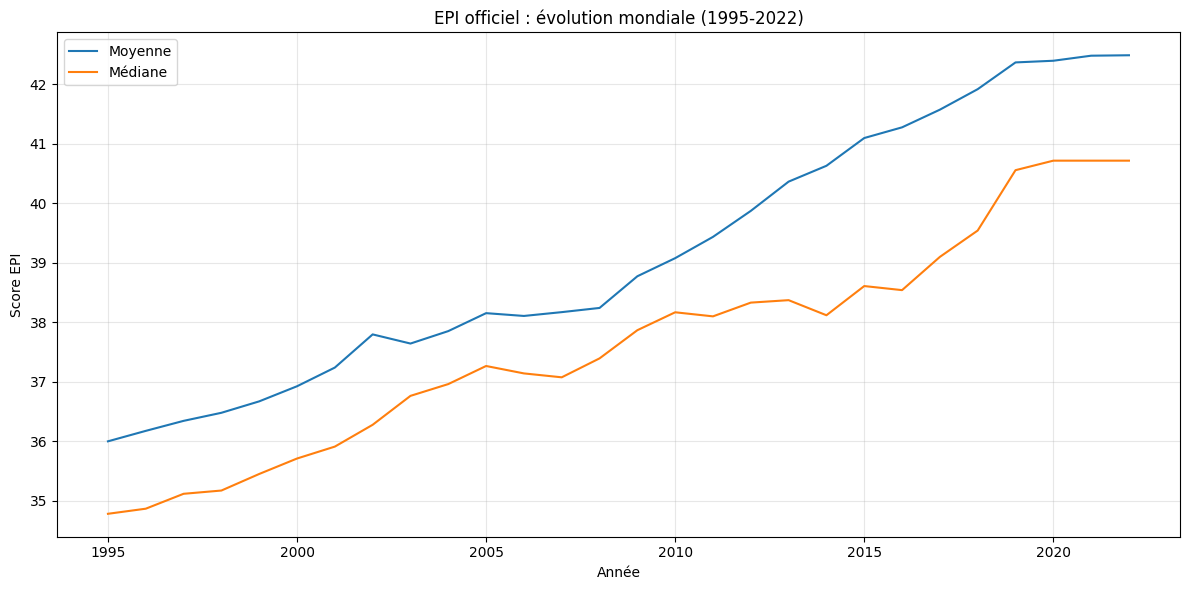

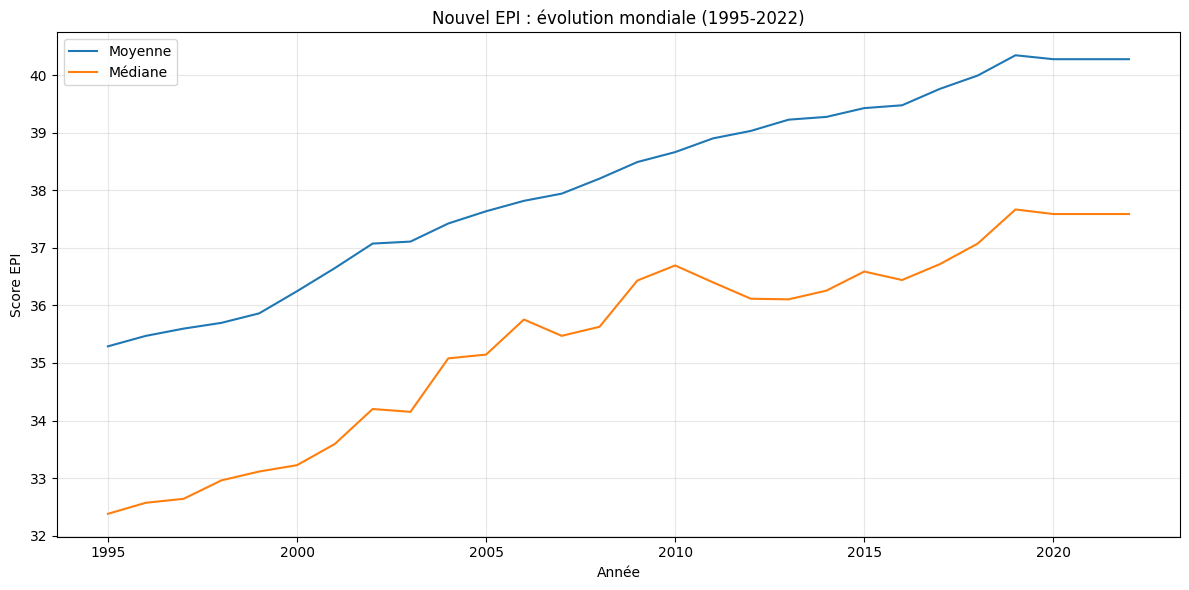

In [7]:
graphique_evolution_epi_moyen_median_mondial(
    df_final, "EPI officiel", "EPI_officiel"
)

graphique_evolution_epi_moyen_median_mondial(
    df_final, "Nouvel EPI", "EPI_new"
)

Les deux indices mettent en évidence une amélioration globale des performances environnementales entre 1995 et 2022. Cette progression est plus marquée pour l'EPI officiel, dont le score moyen augmente d'environ 6,5 points, contre 5 points pour notre nouvel indice. On remarque que l'écart entre la moyenne et la médiane est plus important pour le nouvel EPI, ce qui suggère une distribution des scores plus asymétrique.

### Évolution des performances régionales

Nous étudions ensuite les trajectoires moyennes des régions.

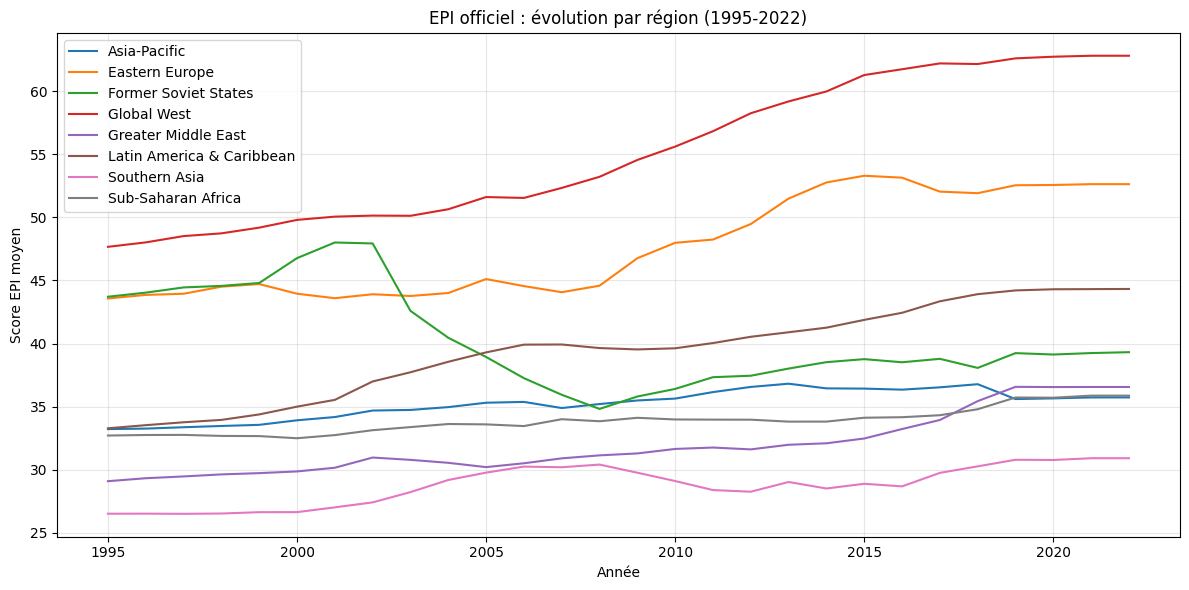

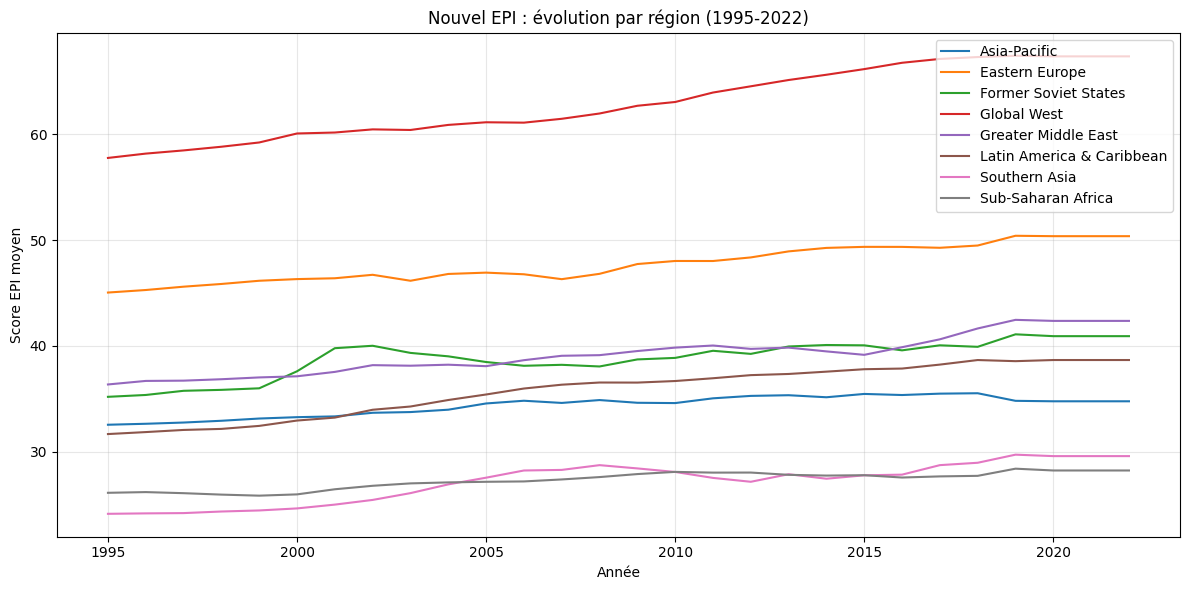

In [8]:
graphique_evolution_epi_moyen_par_region(
    df_final, "EPI officiel", "EPI_officiel"
)

graphique_evolution_epi_moyen_par_region(
    df_final, "Nouvel EPI", "EPI_new"
)

Les nouvelles pondérations accentuent les disparités régionales : en 2022, près de 39 points séparent les pays occidentaux de l'Afrique subsaharienne, contre 27 points avec l'EPI officiel. Cela pourrait s'expliquer par le fait que les pays développés disposent de davantage de moyens pour répondre aux besoins environnementaux humains. On remarque que les anciens États soviétiques régressent avec l'EPI officiel, mais progressent avec notre indice. On peut supposer que l'amélioration des conditions de vie dans ces pays ne s'est pas nécessairement accompagnée d'une amélioration de l'ensemble des dimensions environnementales. Ces hypothèses mériteraient toutefois d'être vérifiées à l'échelle des sous-indices intermédiaires.

### Évolution des performances nationales

Nous identifions les dix pays ayant le plus progressé et les dix ayant le moins progressé entre 1995 et 2022, selon chaque indice.

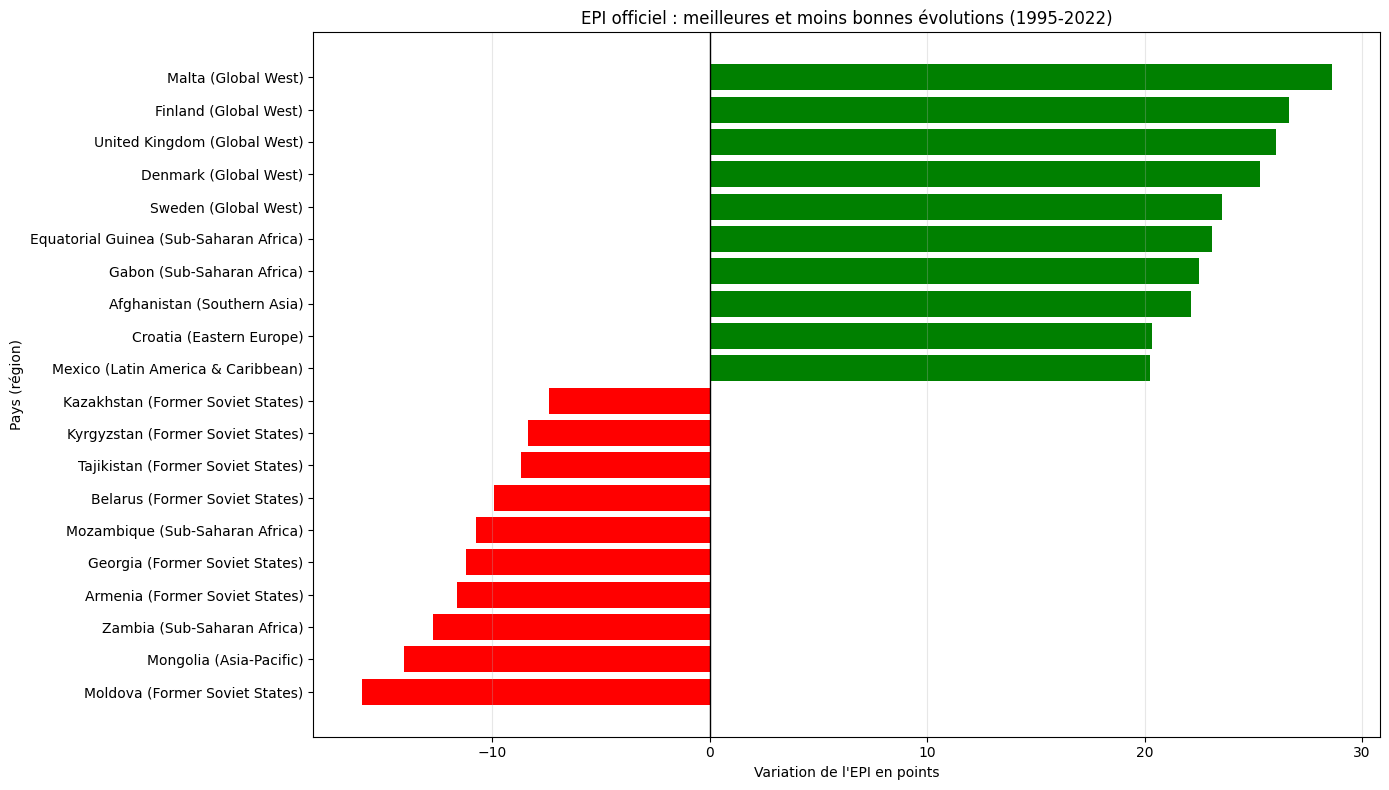

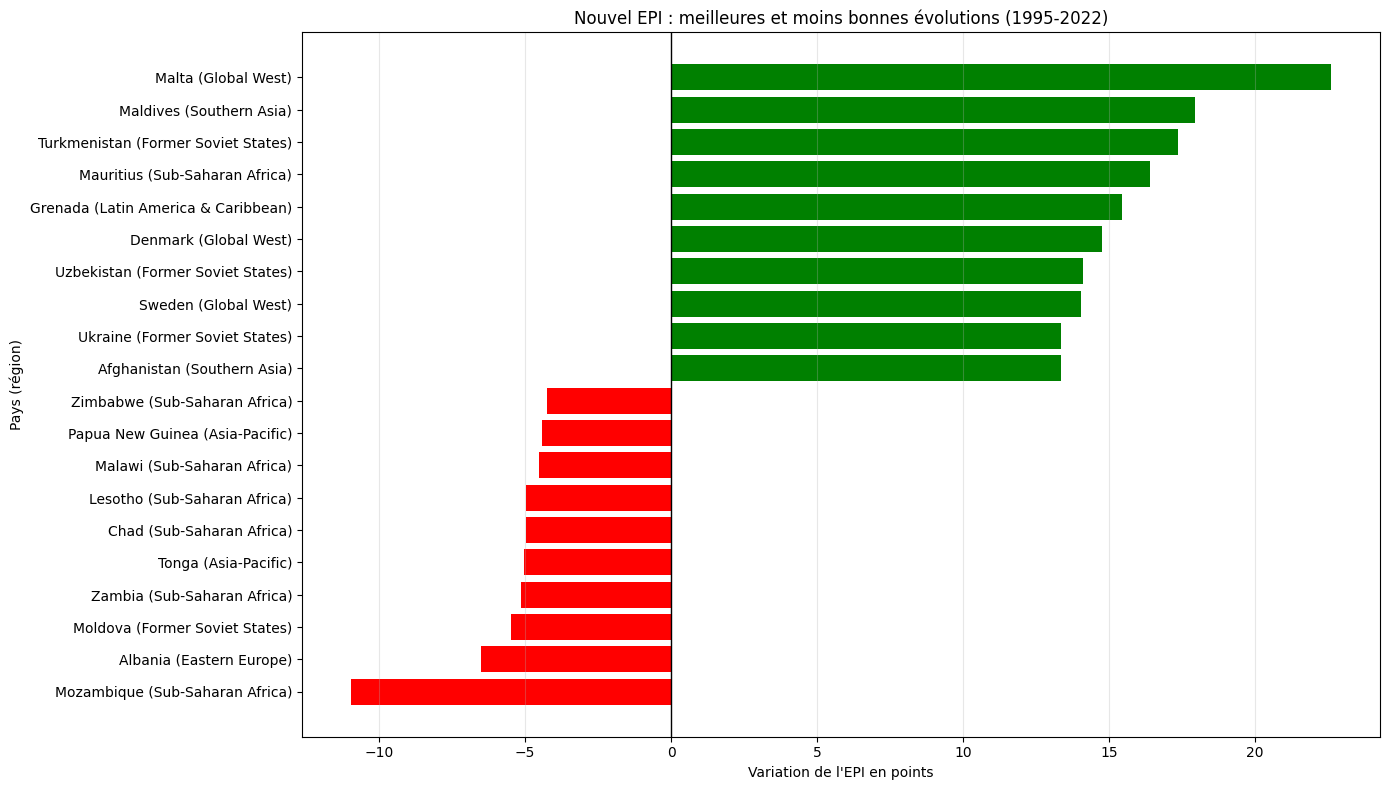

In [9]:
graphique_classement_variation_epi_par_pays(
    df_final, "EPI officiel", "EPI_officiel"
)

graphique_classement_variation_epi_par_pays(
    df_final, "Nouvel EPI", "EPI_new"
)

Si certains pays, comme Malte, le Danemark et la Suède, figurent parmi les meilleures progressions selon les deux indices, les classements diffèrent sensiblement. Avec les nouvelles pondérations, des pays comme le Turkménistan, l'Ouzbékistan et l'Ukraine (anciens États soviétiques) apparaissent parmi les plus fortes progressions, ce qui rejoint nos observations à l'échelle régionale. À l'inverse, les pays d'Afrique subsaharienne sont davantage représentés parmi les plus fortes régressions. Une explication possible serait que les progrès en matière de santé environnementale et d'accès aux ressources essentielles ont été inégalement répartis entre les pays. Notre indice permet ainsi de mettre en lumière des évolutions que l'EPI officiel tend à atténuer.

### Bilan

L'analyse dynamique montre que, si l'amélioration globale des performances environnementales reste observable avec les deux indices, les conclusions à l'échelle régionale et nationale dépendent davantage des pondérations retenues. Pour compléter cette analyse, nous comparons l'évolution du classement international moyen de chaque région entre 1995 et 2022.

In [10]:
tableau_synthese_evolution_par_region(df_final)

,Gain de places (EPI officiel),Gain de places (nouvel EPI)
region,,
Asia-Pacific,-15.08,-10.36
Eastern Europe,6.68,-4.37
Former Soviet States,-51.08,3.00
Global West,13.14,1.95
Greater Middle East,16.25,3.06
Latin America & Caribbean,28.03,10.84
Southern Asia,4.12,15.50
Sub-Saharan Africa,-13.39,-5.59


Le cas des anciens États soviétiques est particulièrement révélateur : ils perdent en moyenne 51 places avec l'EPI officiel, mais en gagnent 3 avec notre indice. À l'inverse, l'Europe de l'Est voit sa progression se transformer en recul. Les choix de construction d'un indice influencent non seulement notre perception des performances environnementales, mais aussi celle des progrès réalisés au cours du temps. Ces résultats restent  à nuancer compte tenu des limites de la reconstruction historique et du traitement des valeurs manquantes.